# Evaluate ttl timing relative to Npx/Analog channels

## Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os
import spikeinterface.full as si
import pynapple as nap

## Functions

In [2]:
def readMeta(binFullPath):
    metaName = binFullPath.stem + ".meta"
    metaPath = Path(binFullPath.parent / metaName)
    metaDict = {}
    if metaPath.exists():
        # print("meta file present")
        with metaPath.open() as f:
            mdatList = f.read().splitlines()
            # convert the list entries into key value pairs
            for m in mdatList:
                csList = m.split(sep='=')
                if csList[0][0] == '~':
                    currKey = csList[0][1:len(csList[0])]
                else:
                    currKey = csList[0]
                metaDict.update({currKey: csList[1]})
    else:
        print("no meta file")
    return(metaDict)

def define_epochs(onsets, durations, pre_win=.505, post_win=1):
    # Create start and end times for each trial
    start_times = onsets - pre_win
    end_times = onsets + durations + post_win

    # Create an IntervalSet
    extract_windows = nap.IntervalSet(start=start_times, end=end_times)
    return extract_windows

def extract_trace_epochs(rec, rec_ch, event_onsets, event_durations, pre_win=.505, post_win=1):
    # Define epoch windows
    extract_windows = define_epochs(event_onsets, event_durations, pre_win=pre_win, post_win=post_win)
    SampRate = rec.get_sampling_frequency()

    # Extract data epochs
    extracted_epochs = []
    epoch_times = []
    epoch_times_zero_aligned = []
    for epoch_start, epoch_end in extract_windows.values:
        # Convert seconds to sample indices
        start_frame = int(epoch_start * SampRate)
        end_frame = int(epoch_end * SampRate)

        # Extract current window
        curr_win = rec.get_traces(segment_index=0,
          start_frame=start_frame, end_frame=end_frame,
          channel_ids=[rec.channel_ids[rec_ch]], return_in_uV=True).flatten()
        
        # Get curr_win times and zero_aligned
        curr_times = np.linspace(epoch_start, epoch_end, len(curr_win)) 
        curr_times_zero_aligned = curr_times - epoch_start - pre_win 

        # Store curr_win and curr_times
        extracted_epochs.append(curr_win)
        epoch_times.append(curr_times)
        epoch_times_zero_aligned.append(curr_times_zero_aligned)
        
    return extracted_epochs, epoch_times, epoch_times_zero_aligned

## Define paths and parameters to access data

In [3]:
# General information
recording = 'M296_3'
ttl_type = 'obx_stim_pulses'
ttl_ch = 4 # stim pulse ttl, plb ttl...
npx_ch = 50 # Ap channel
stim_durations = {'tr100ms':0.1, 'tr1s':1}

# Paths and file names
obx_path = r"M:\test_Stim_g0"
obx_bin_name = "test_Stim_g0_t0.obx0.obx.bin"
npx_path = r"M:\test_Stim_g0\test_Stim_g0_imec0\catgt_test_Stim_g0"
ttl_times_path = r"M:\test_Stim_g0\test_Stim_g0_imec0\catgt_test_Stim_g0"
tlt_times_csv_name = r"M296_3_obx_stim_pulses_exp_summary.csv"

# Define saving folder for plots - Write None if dont want to save plots
save_folder = r"M:\test_Stim_g0\test_Stim_g0_imec0\catgt_test_Stim_g0"

In [4]:
# Fixed parameters
pre_win = .505
post_win = 1
zero_time = False # Show plots aligned to zero
npx_data_type = 'car_filtered'

## Load data

**Ttl events**

In [5]:
# Load ttl event times to extract corresponding obx/npx epochs
ttl_times_file = Path(ttl_times_path, tlt_times_csv_name)
ttl_times_df = pd.read_csv(ttl_times_file)
ttl_times_df["stim_dur"] = ttl_times_df["s_names"].map(stim_durations)
ttl_onsets = ttl_times_df['s_times'].to_numpy()
ttl_durations =  ttl_times_df['stim_dur'].to_numpy()

**Event data traces (stim pulse/playbacks)**

In [6]:
## Load obx data and metadata
obx_full_path = Path(obx_path, obx_bin_name)
obx_meta = readMeta(obx_full_path);
obx_SampRate = float(obx_meta['obSampRate'])
obx_gain_factor = float(obx_meta['obAiRangeMax']) / float(obx_meta['obMaxInt']) # in Volts

# Create obx recording object
obx_rec = si.read_binary(obx_full_path, sampling_frequency=obx_SampRate,
                dtype=np.int16, num_channels=int(obx_meta['nSavedChans']),
                gain_to_uV=obx_gain_factor, offset_to_uV=0); # # in Volts

# Extract ttl traces corresponding to ttl epochs
obx_traces, obx_trace_times, obx_time_za = extract_trace_epochs(obx_rec, ttl_ch,
                            ttl_onsets, ttl_durations, pre_win=pre_win, post_win=post_win)

# Add ttl traces and times to ttl_times_df
ttl_times_df["obx_traces"] = obx_traces
ttl_times_df["obx_trace_times"] = obx_trace_times
ttl_times_df["obx_time_za"] = obx_time_za

**Neural data traces**

In [7]:
## Load npx data
npx_rec = si.read_spikeglx(npx_path, stream_name='imec0.ap')
npx_SampRate = npx_rec.get_sampling_frequency()

# Extract npx traces (target channel) corresponding to ttl epochs
npx_traces, npx_trace_times, npx_time_za = extract_trace_epochs(npx_rec, npx_ch,
                            ttl_onsets, ttl_durations, pre_win=pre_win, post_win=post_win) # in uV

# Add npx traces and times to ttl_times_df
ttl_times_df["npx_traces"] = npx_traces
ttl_times_df["npx_trace_times"] = npx_trace_times
ttl_times_df["npx_time_za"] = npx_time_za

## Plot Npx channel and event ttl

In [8]:
if save_folder is not None:
    # Create saving_folder name, and check if save_folder exists, if not, create
    save_folder = Path(save_folder, f"stim_ttl_check_{ttl_type}_{npx_data_type}")
    os.makedirs(save_folder, exist_ok=True)

In [9]:
# Define correction factors - write minus if subtraction
correct_times = False
correct_dict = {'tr100ms':-33, 'tr200ms':-40, 'tr400ms':-49, 'tr600ms':-57, 'tr800ms':-66, 'tr1s':-76, 'tr2s':-86, 'tr4s':-94, 'tr150ms':-102}

Displaying first trial.


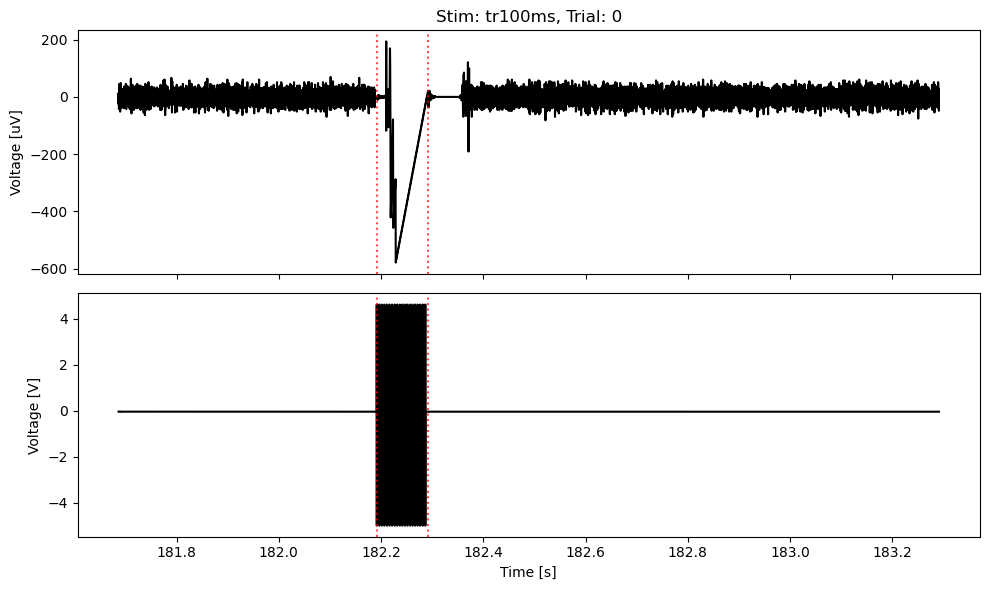

Displaying first trial.


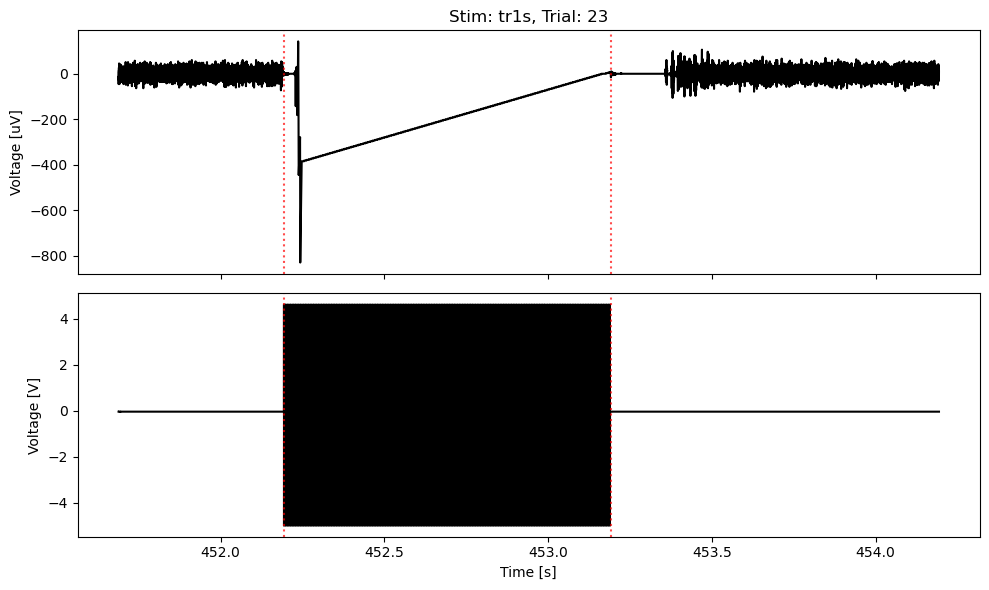

In [10]:
# Plot obx, npx traces in a loop
seen_labels = set() # Initialize a set to track which labels have been displayed
for row in ttl_times_df.itertuples(): 
    # Get current trace and time
    obx_trace = row.obx_traces
    npx_trace = row.npx_traces

    if zero_time:
        obx_times = row.obx_time_za
        npx_times = row.npx_time_za
        x_time_label = "Time [ms]"
        x_scalef = 1000
    else:
        obx_times = row.obx_trace_times
        npx_times = row.npx_trace_times
        x_time_label = "Time [s]"
        x_scalef = 1

    # Get zero_time
    obx_zero_shift_idx = int(np.abs(pre_win) * obx_SampRate) # Find sample where time = 0
    obx_zero_onset = obx_times[obx_zero_shift_idx]
    obx_zero_offset = obx_zero_onset + row.stim_dur
    npx_zero_shift_idx = int(np.abs(pre_win) * npx_SampRate) # Find sample where time = 0
    npx_zero_onset = npx_times[npx_zero_shift_idx]
    npx_zero_offset = npx_zero_onset + row.stim_dur


    # Start figure
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    # Plot current npx trace
    ax[0].plot(npx_times * x_scalef, npx_trace, color='black')
    ax[0].set_ylabel("Voltage [uV]")
    t_index = row.trial if hasattr(row, 'trial') else row.Index
    ax[0].set_title(f"Stim: {row.s_names}, Trial: {t_index}")
    
    # Plot onset/offset in npx trace
    ax[0].axvline(x=npx_zero_onset, color='red', linestyle=':', alpha=0.7)
    ax[0].axvline(x=npx_zero_offset, color='red', linestyle=':', alpha=0.7)
    
    # Plot current event trace (obx)
    ax[1].plot(obx_times * x_scalef, obx_trace, color='black')
    ax[1].set_xlabel(x_time_label)
    ax[1].set_ylabel("Voltage [V]")

    # Plot onset/offset in event trace (obx)
    ax[1].axvline(x=obx_zero_onset, color='red', linestyle=':', alpha=0.7)
    ax[1].axvline(x=obx_zero_offset, color='red', linestyle=':', alpha=0.7)

    # Plot corrected onset in npx
    if correct_times:
        current_correctf = correct_dict[row.s_names]
        corr_onset = obx_zero_onset + current_correctf
        ax[1].axvline(x=corr_onset, color='blue', linestyle=':', alpha=0.7)
    #ax[1].set_xticks([-1, 0, 1])
    
    plt.tight_layout()

    # Save every plot to your save_folder
    save_name = Path(save_folder, f"ttl_aligned_pulse_{row.s_names}_{t_index}.png")
    fig.savefig(save_name)

    # Display only the first example for each stim type
    if row.s_names not in seen_labels:
        print("Displaying first trial.")
        plt.show() 
        seen_labels.add(row.s_names) # Mark this label as seen

    # Close the figure to optimize RAM
    plt.close(fig)

Fin